# Selected High- and Low-Relevance Firms on the Main Relevance Score, Colored by Sector

| Item | Description |
|---|---|
| Goal | Generate a standalone, publication-ready figure and a compact CSV dataset for a selected subsample of prominent high-relevance and low-relevance firms on the main topic relevance measure (cosine similarity between firm-level 10-K Item 1 summaries and the congressional policy summary). |
| Input |  (wide relevance scores);  (Compustat NAICS codes); or directly . |
| Output |  (compact CSV of the 18 selected firms with scores, demeaned scores, and NAICS sectors) and . |
| Selected Firms | **High Side (14 firms)**: Visa, Nielsen, Alphabet, Verizon, Qualcomm, Cisco, Apple, Allstate, Amazon, Equifax, Microsoft, Mastercard, Oracle, GE Healthcare.<br>**Low Side (4 firms)**: Kansas City Southern, Morgan Stanley, Norwegian Cruise Line Holdings, Pepsi Bottling Group. |
| Measure |  demeaned by the sample mean over all 1,058 firms (0.5121). |


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import Patch


## Step 2. Define file locations, the measure, the industry names, and the wording

The wording is built from the same two phrases as T3.9.1 to T3.9.3. The subsector names are NAICS 2022 names, shortened where a name is long; codes that exist only in older NAICS vintages are named by that vintage.


In [2]:
from pathlib import Path

# Paths relative to repository root for local execution and GitHub compatibility
NOTEBOOK_DIR = Path.cwd()
# If executed from inside this directory or project root
PROJECT_FOLDER = NOTEBOOK_DIR if (NOTEBOOK_DIR / "T3 - Topic Relevance and Corporate Disclosure").exists() else NOTEBOOK_DIR.parents[2]
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.5"
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
CONTROLS_FILE = PROJECT_FOLDER / "T4 - Toy Example [Topic Relevance on Privacy Innovation]/compustat/compustat_controls.csv"
SELECTED_CSV_FILE = OUTPUT_FOLDER / "selected_firms_relevance_scores.csv"

SAMPLE = "all_years"
MEASURE_ID = "summaries | policy_summary | firm_summary"

NAICS_SECTORS = {
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services (except public administration)"
}

NAICS_SUBSECTORS = {
    "111": "Crop Production", "112": "Animal Production and Aquaculture", "113": "Forestry and Logging", "114": "Fishing, Hunting and Trapping", "115": "Support Activities for Agriculture and Forestry",
    "211": "Oil and Gas Extraction", "212": "Mining (except Oil and Gas)", "213": "Support Activities for Mining", "221": "Utilities", "236": "Construction of Buildings",
    "237": "Heavy and Civil Engineering Construction", "238": "Specialty Trade Contractors", "311": "Food Manufacturing", "312": "Beverage and Tobacco Product Manufacturing",
    "313": "Textile Mills", "314": "Textile Product Mills", "315": "Apparel Manufacturing", "316": "Leather and Allied Product Manufacturing", "321": "Wood Product Manufacturing",
    "322": "Paper Manufacturing", "323": "Printing and Related Support Activities", "324": "Petroleum and Coal Products Manufacturing", "325": "Chemical Manufacturing",
    "326": "Plastics and Rubber Products Manufacturing", "327": "Nonmetallic Mineral Product Manufacturing", "331": "Primary Metal Manufacturing", "332": "Fabricated Metal Product Manufacturing",
    "333": "Machinery Manufacturing", "334": "Computer and Electronic Product Manufacturing", "335": "Electrical Equipment, Appliance, and Component Manufacturing",
    "336": "Transportation Equipment Manufacturing", "337": "Furniture and Related Product Manufacturing", "339": "Miscellaneous Manufacturing", "423": "Merchant Wholesalers, Durable Goods",
    "424": "Merchant Wholesalers, Nondurable Goods", "425": "Wholesale Electronic Markets and Agents and Brokers", "441": "Motor Vehicle and Parts Dealers", "444": "Building Material and Garden Equipment and Supplies Dealers",
    "445": "Food and Beverage Retailers", "449": "Furniture, Home Furnishings, Electronics, and Appliance Retailers", "455": "General Merchandise Retailers", "456": "Health and Personal Care Retailers",
    "457": "Gasoline Stations and Fuel Dealers", "458": "Clothing, Clothing Accessories, Shoe, and Jewelry Retailers", "459": "Sporting Goods, Hobby, Musical Instrument, Book, and Miscellaneous Retailers",
    "481": "Air Transportation", "482": "Rail Transportation", "483": "Water Transportation", "484": "Truck Transportation", "485": "Transit and Ground Passenger Transportation",
    "486": "Pipeline Transportation", "487": "Scenic and Sightseeing Transportation", "488": "Support Activities for Transportation", "492": "Couriers and Messengers",
    "493": "Warehousing and Storage", "511": "Publishing Industries, except Internet (NAICS 2017)", "512": "Motion Picture and Sound Recording Industries",
    "513": "Publishing Industries", "516": "Authoring, Publishing, and Web Search Portals", "517": "Telecommunications", "518": "Computing Infrastructure and Data Processing",
    "519": "Web Search Portals and Other Information Services", "521": "Monetary Authorities-Central Bank", "522": "Credit Intermediation and Related Activities",
    "523": "Securities, Commodity Contracts, and Other Financial Investments", "524": "Insurance Carriers and Related Activities", "525": "Funds, Trusts, and Other Financial Vehicles",
    "531": "Real Estate", "532": "Rental and Leasing Services", "533": "Lessors of Nonfinancial Intangible Assets", "541": "Professional, Scientific, and Technical Services",
    "551": "Management of Companies and Enterprises", "561": "Administrative and Support Services", "562": "Waste Management and Remediation Services",
    "611": "Educational Services", "621": "Ambulatory Health Care Services", "622": "Hospitals", "623": "Nursing and Residential Care Facilities",
    "624": "Social Assistance", "711": "Performing Arts, Spectator Sports, and Related Industries", "712": "Museums, Historical Sites, and Similar Institutions",
    "713": "Amusement, Gambling, and Recreation Industries", "721": "Accommodation", "722": "Food Services and Drinking Places", "811": "Repair and Maintenance",
    "812": "Personal and Laundry Services", "813": "Religious, Grantmaking, Civic, Professional, and Similar Organizations"
}

SECTOR_TITLES = {
    "11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction", "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
    "42": "Wholesale Trade", "44": "Retail Trade", "45": "Retail Trade", "48": "Transportation", "49": "Transportation", "51": "Information",
    "52": "Finance and Insurance", "53": "Real Estate", "54": "Professional and Technical Services", "55": "Management of Companies",
    "56": "Administrative and Support Services", "61": "Educational Services", "62": "Health Care", "71": "Arts and Entertainment", "72": "Accommodation and Food Services", "81": "Other Services"
}

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")

Outputs: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.5


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. Eight group colors in a fixed order, the first four pinned to the sectors of T3.9.2 at the two-digit level (information RED, mining BLUE, manufacturing ORANGE, finance and insurance GREEN), and GREY for the grouped other groups. Fifty rows per figure, so the firm names are small.


In [3]:
RED = "#B31942"          # Information sector companies
SLATE_GREY = "#5A6B7C"   # Other sectors
BLACK = "#101820"
GRID_COLOR = "#E0E0E0"

FIGURE_WIDTH = 8.5
FIGURE_HEIGHT = 6.5
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3
BAR_HEIGHT = 0.75
FIRM_LABEL_SIZE = 9
LEGEND_FONT_SIZE = 9
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11

## Step 4. Load the scores, tidy the firm names, and attach the NAICS sector and subsector

The wide table of T3.8.3, the chosen sample only. Compustat names are upper case; they are shown in title case with the common suffixes kept short, as in T3.9.2. The sector comes from the link file exactly as in T3.9.1 to T3.9.3; the subsector is the first three digits of the same code, and every code must have a name.


In [4]:
# Load wide scores and Compustat controls to build/refresh the compact dataset if needed
if not SELECTED_CSV_FILE.exists():
    wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
    wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
    wide["gvkey"] = wide["gvkey"].astype(str).str.zfill(6)
    
    ctrls = pd.read_csv(CONTROLS_FILE, dtype={"gvkey": str})
    ctrls["gvkey"] = ctrls["gvkey"].str.zfill(6)
    naics_map = ctrls.dropna(subset=["naics"]).drop_duplicates("gvkey").set_index("gvkey")["naics"]
    wide["naics"] = wide["gvkey"].map(naics_map).astype(int).astype(str)
    wide["naics2"] = wide["naics"].str[:2]
    wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
    wide["naics3"] = wide["naics"].str[:3]
    wide["subsector"] = wide["naics3"].map(NAICS_SUBSECTORS)
    
    pop_mean = float(wide[MEASURE_ID].mean())
    wide["demeaned"] = wide[MEASURE_ID] - pop_mean
    wide["display_name"] = wide["conm"].str.title().str.replace(r"\s+-Cl\s+\w+$", "", regex=True).str.replace(r"Inc$", "Inc.", regex=True).str.replace(r"Corp$", "Corp.", regex=True)
    
    target_gvkeys = {
        "179534": "highest", # Visa
        "100873": "highest", # Nielsen
        "160329": "highest", # Alphabet
        "002136": "highest", # Verizon
        "024800": "highest", # Qualcomm
        "020779": "highest", # Cisco
        "001690": "highest", # Apple
        "028349": "highest", # Allstate
        "064768": "highest", # Amazon
        "004423": "highest", # Equifax
        "012141": "highest", # Microsoft
        "160225": "highest", # Mastercard
        "012142": "highest", # Oracle
        "041818": "highest", # GE Healthcare
        "006335": "lowest",  # Kansas City Southern
        "012124": "lowest",  # Morgan Stanley
        "104432": "lowest",  # Norwegian Cruise Line
        "119417": "lowest",  # Pepsi Bottling Group
    }
    sub = wide[wide["gvkey"].isin(target_gvkeys.keys())].copy()
    sub["end"] = sub["gvkey"].map(target_gvkeys)
    sub = sub.sort_values(MEASURE_ID, ascending=False).reset_index(drop=True)
    out_cols = ["end", "gvkey", "conm", "display_name", "naics", "naics2", "sector", "naics3", "subsector", MEASURE_ID, "demeaned"]
    sub[out_cols].to_csv(SELECTED_CSV_FILE, index=False, float_format="%.6f")
    print(f"Created {SELECTED_CSV_FILE}")

# Read directly from the compact CSV for plotting and easy manipulation
drawn = pd.read_csv(SELECTED_CSV_FILE, dtype={"gvkey": str, "naics": str})
display(drawn[["end", "display_name", "sector", MEASURE_ID, "demeaned"]])

,end,display_name,sector,summaries | policy_summary | firm_summary,demeaned
0,highest,Visa Inc.,Finance and insurance,0.620883,0.108778
1,highest,Nielsen Holdings Plc,"Professional, scientific, and technical services",0.613060,0.100955
2,highest,Alphabet Inc.,Information,0.609440,0.097335
3,highest,Verizon Communications Inc.,Information,0.607030,0.094925
4,highest,Qualcomm Inc.,Manufacturing,0.600682,0.088577
5,highest,Cisco Systems Inc.,Manufacturing,0.595573,0.083468
6,highest,Apple Inc.,Manufacturing,0.594128,0.082023
7,highest,Allstate Corp.,Finance and insurance,0.591812,0.079707
8,highest,Amazon.Com Inc.,Retail trade,0.591493,0.079388
9,highest,Equifax Inc.,Administrative and support and waste management,0.591470,0.079365


## Step 5. Pick the firms at both ends, demean, and assign the color groups

The score minus the mean over all sample firms; the `N_FIRMS` highest and the `N_FIRMS` lowest, each ordered from the highest to the lowest score. In each figure, groups with at least `MIN_FIRMS_COLORED` of its firms take a color in order of firm count, pinned colors first, up to `MAX_COLORED` groups; every other group is drawn as other. The drawn firms are saved with their groups.


In [5]:
high_part = drawn[drawn["end"].eq("highest")].sort_values("demeaned", ascending=False).reset_index(drop=True)
low_part = drawn[drawn["end"].eq("lowest")].sort_values("demeaned", ascending=False).reset_index(drop=True)

print(f"Selected High Firms: {len(high_part)}")
print(f"Selected Low Firms: {len(low_part)}")

Selected High Firms: 14
Selected Low Firms: 4


## Step 6. Draw the four figures

For each level and each end, one horizontal bar per firm, ordered from the highest score at the top to the lowest at the bottom, bars running from zero (the sample mean) to the firm's demeaned score, colored by group, with a solid BLACK zero line. The X range is the same in all four figures. No text inside the plot. The legend names the groups present in the figure and sits 0.5 cm above the bottom edge with the most columns that fit between the side margins; the X-title ends 0.5 cm above the legend and the firm names start 0.5 cm from the left edge after the Y-title.


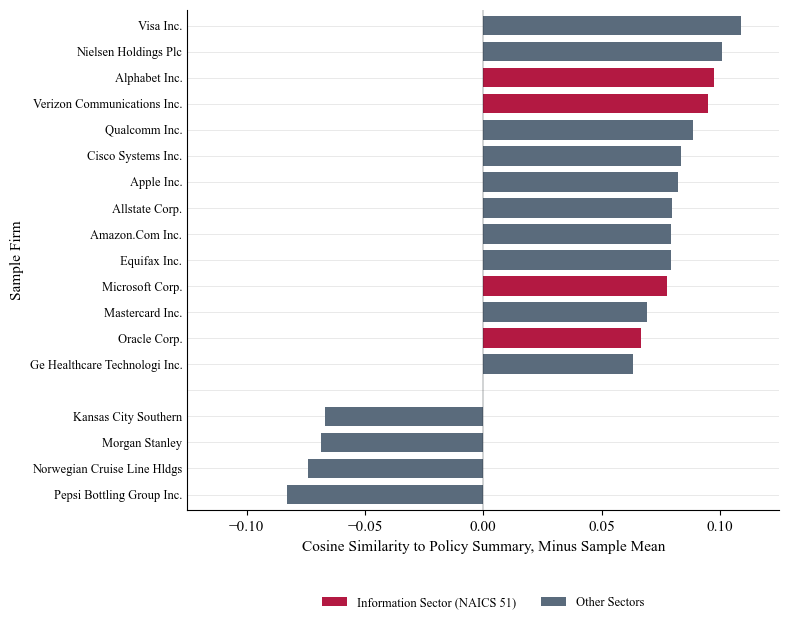

Saved updated fig_selected_high_and_low_relevance_firms_by_sector (.png, .svg, .pdf) in /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.5


In [6]:
from matplotlib.patches import Patch

# Y-axis labels: firm names without NAICS codes for a clean look
high_labels = high_part["display_name"].tolist()
low_labels = low_part["display_name"].tolist()
all_labels = high_labels + [""] + low_labels

positions = np.arange(len(all_labels))[::-1]
high_pos = positions[:len(high_labels)]
low_pos = positions[len(high_labels) + 1:]

# Highlight Information companies in RED, others in neutral slate grey
high_colors = [RED if s == "Information" else SLATE_GREY for s in high_part["sector"]]
low_colors = [RED if s == "Information" else SLATE_GREY for s in low_part["sector"]]

reach = max(abs(drawn["demeaned"].min()), abs(drawn["demeaned"].max())) * 1.15

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.28, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.20)

ax.barh(high_pos, high_part["demeaned"], color=high_colors, height=BAR_HEIGHT, zorder=2)
ax.barh(low_pos, low_part["demeaned"], color=low_colors, height=BAR_HEIGHT, zorder=2)
ax.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)

ax.set_yticks(positions)
ax.set_yticklabels(all_labels)
ax.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
ax.set_xlim(-reach, reach)
ax.set_xlabel("Cosine Similarity to Policy Summary, Minus Sample Mean")
ax.set_ylabel("Sample Firm")
ax.tick_params(axis="y", length=0, labelsize=FIRM_LABEL_SIZE)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.5)
ax.set_axisbelow(True)

# Clean binary legend highlighting Information sector
legend_handles = [Patch(facecolor=RED), Patch(facecolor=SLATE_GREY)]
legend_labels = ["Information Sector (NAICS 51)", "Other Sectors"]

ax.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.22),
          ncol=2, frameon=False, fontsize=LEGEND_FONT_SIZE)

figure_name = "fig_selected_high_and_low_relevance_firms_by_sector"
for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")

plt.show()
print(f"Saved updated {figure_name} (.png, .svg, .pdf) in {OUTPUT_FOLDER}")

## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order: the two-digit level first, highest then lowest, and then the three-digit level.


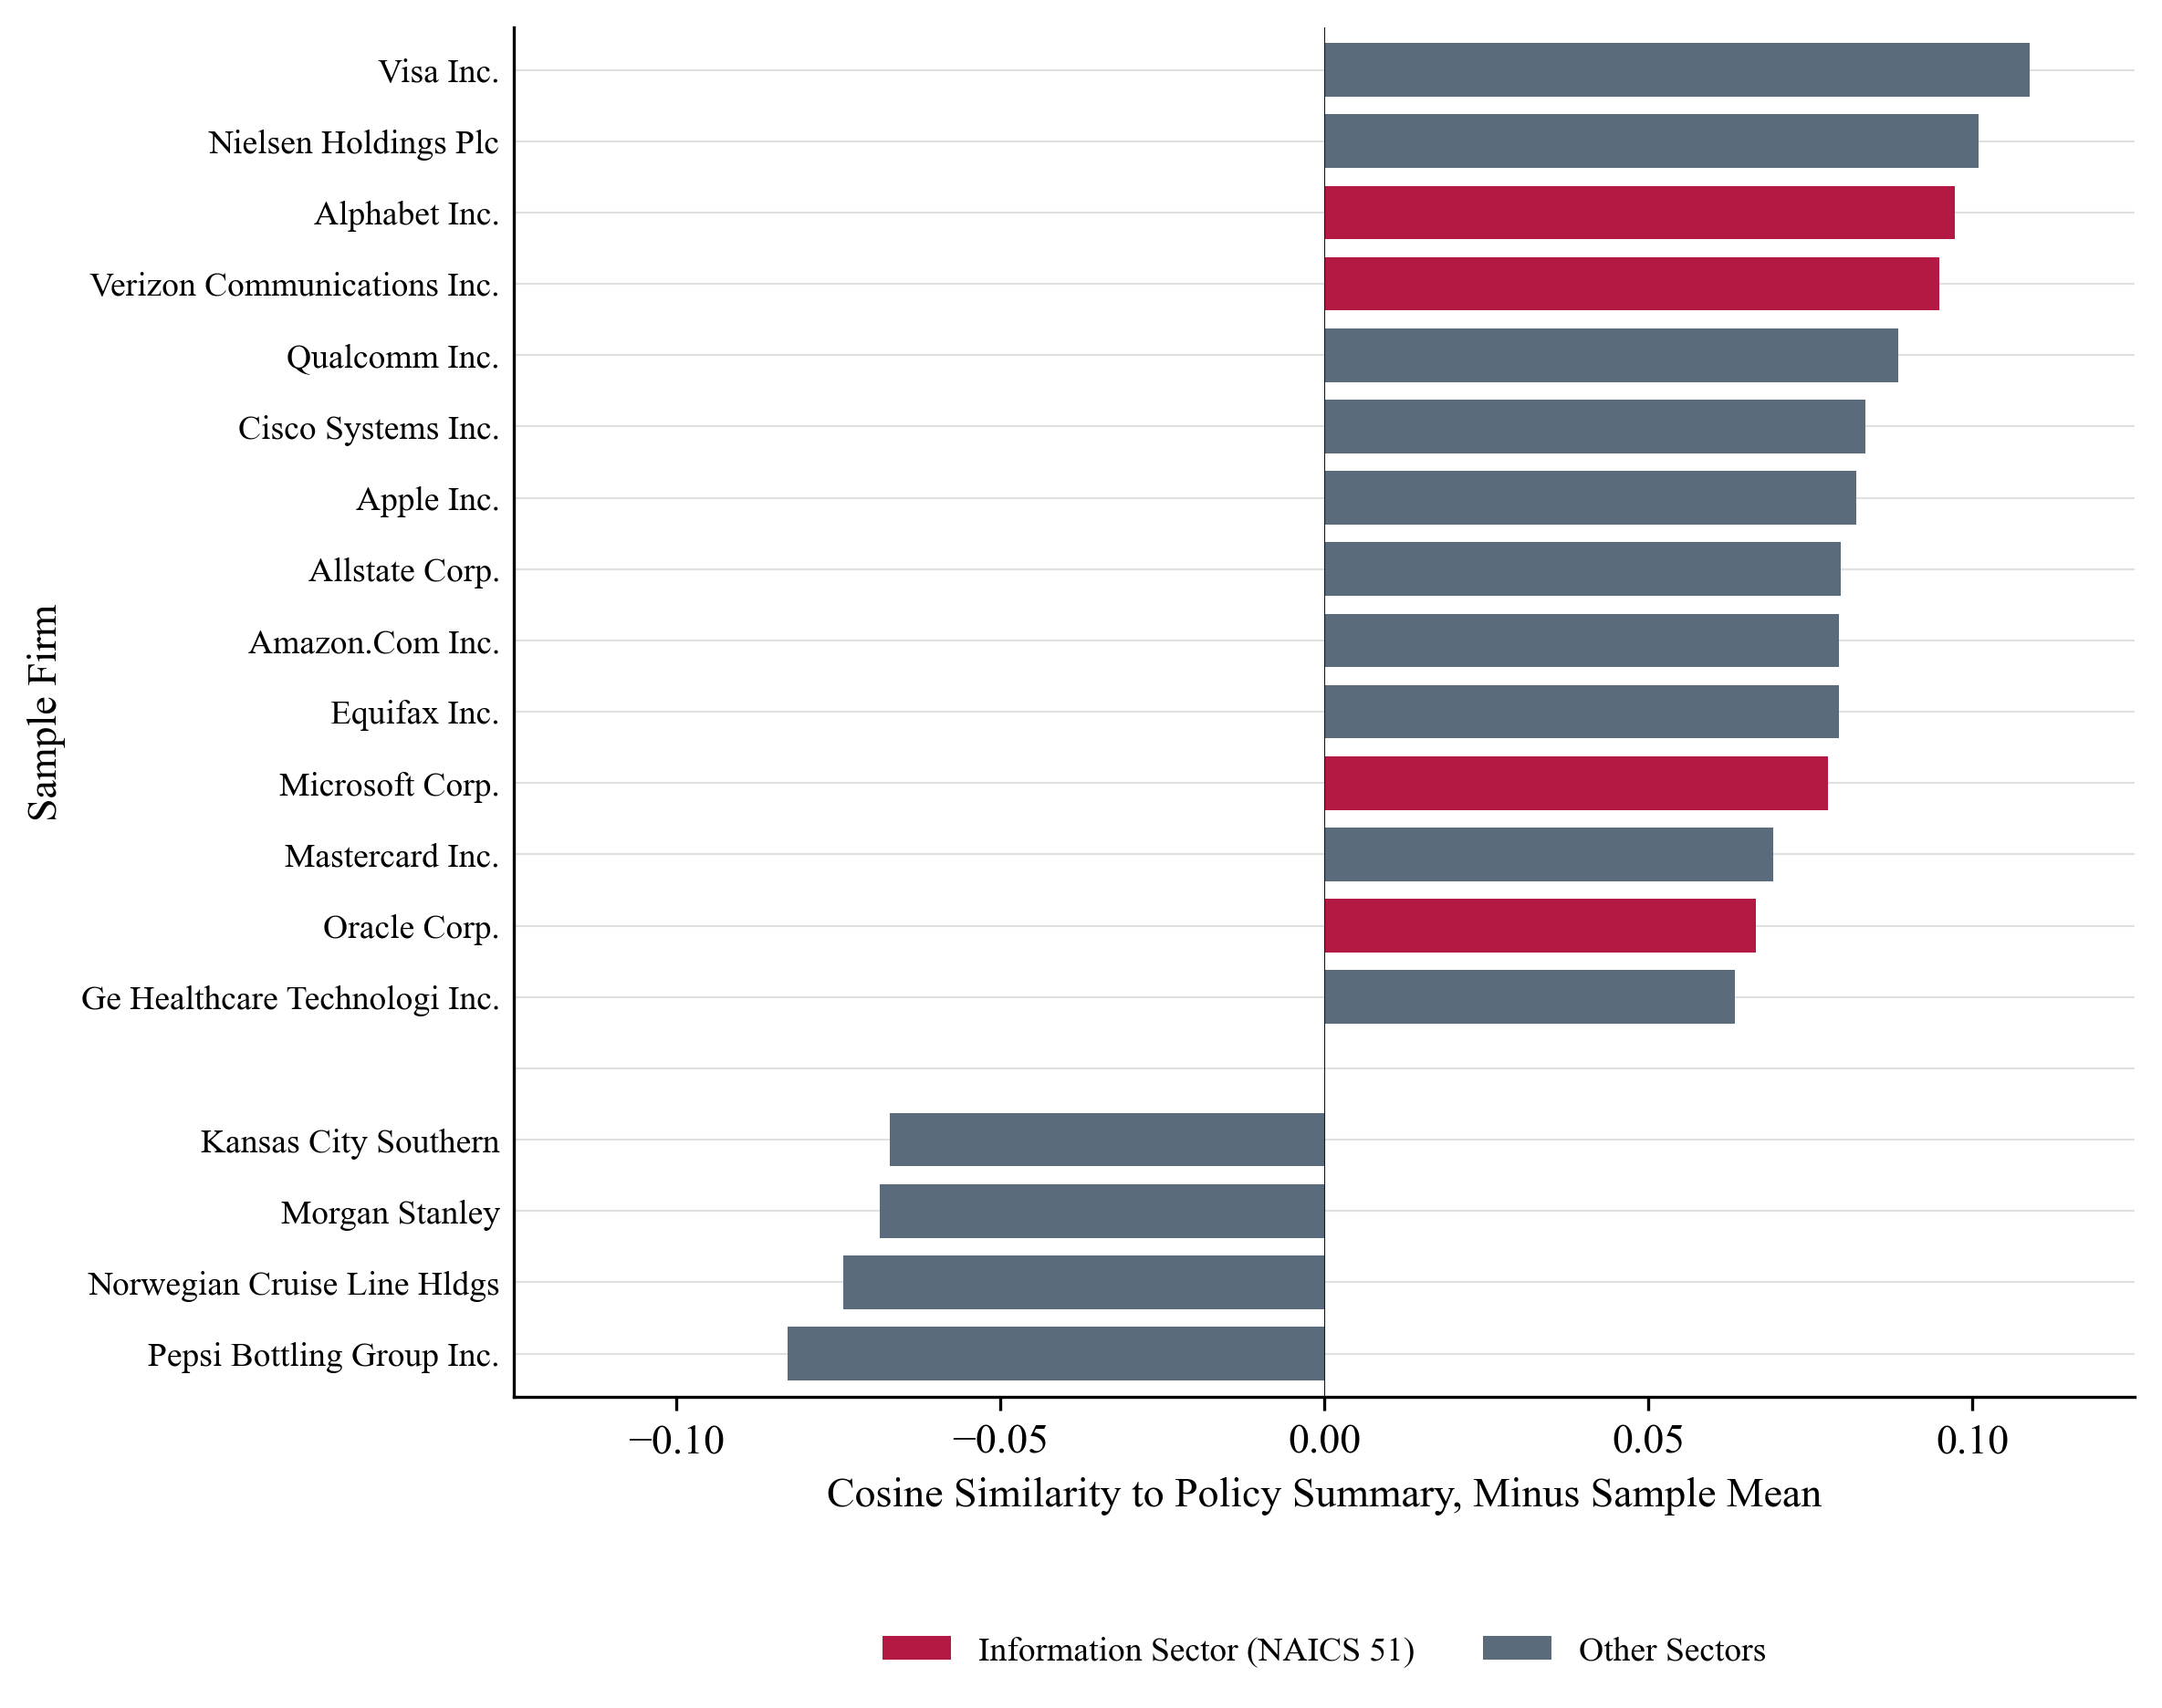

In [7]:
from IPython.display import Image, display
display(Image(filename=OUTPUT_FOLDER / "fig_selected_high_and_low_relevance_firms_by_sector.png"))

## Step 8. Figure for Filtered Selection of Firms (Matching Panel A Aspect Ratio)

This section updates the horizontal bar chart for the firms indicated in `T4 - Toy Example [Topic Relevance on Privacy Innovation]/patents/firm_topic_relevance_forfigure.csv` by filtering out the middle cohort between Albertsons and Kraft, and adjusting the aspect ratio to 1.5 (9.0 × 6.0 in, 2700 × 1800 px at 300 DPI) to match Panel A identically.

- **High Relevance Cohort (Above Albertsons, 14 firms):** Pure digital, cybersecurity, mobile hardware, enterprise software, and payment platform leaders (Visa, Nielsen, Alphabet, Motorola Mobility, ADT, CrowdStrike, Palo Alto Networks, Cisco, Apple, Amazon, Mastercard, Oracle, Salesforce, Meta Platforms).
- **Low Relevance Cohort (Below Kraft, 8 firms):** Traditional old-economy baseline firms across manufacturing, mining, beverages, transport, and retail (Brown-Forman, Anheuser-Busch, Molson Coors, Marathon Oil, Morgan Stanley, Norwegian Cruise Line, Pepsi Bottling, Pep Boys).
- **Middle Cohort Removed (Albertsons to Kraft, 11 firms):** Ambiguous/low-exposure retail, defense, airline, conglomerate, chemical, and food entities (Albertsons, Raytheon, American Airlines, Target, Live Nation, Moody's, Southwest Airlines, General Mills, Citigroup, Eastman Chemical, Kraft Foods).

The scores report the cosine similarity between each firm's 10-K summary and the privacy policy summary demeaned by the overall sample mean ($0.5121$) across all 1,058 firms. Bars are color-coded to distinguish Information sector companies (NAICS 51, crimson red `#B31942`) from other sectors (slate grey `#5A6B7C`).

Synchronized figure to /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/X - Drafts and Documentation/figures/fig3_panel_b_top_firms.png


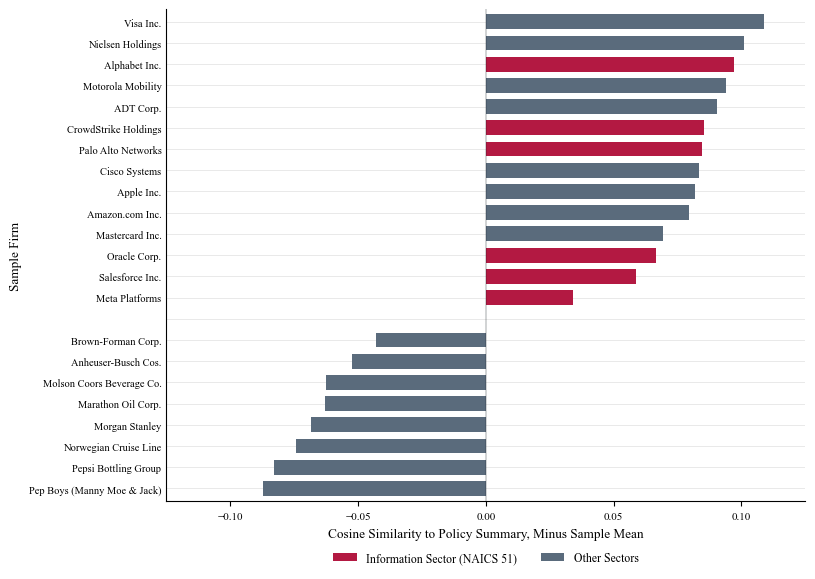

Saved fig_selected_firms_from_csv_relevance (.png, .svg, .pdf) in /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.5


In [8]:
# Load marked firms from CSV and Compustat controls
marked_csv_path = PROJECT_FOLDER / "T4 - Toy Example [Topic Relevance on Privacy Innovation]/patents/firm_topic_relevance_forfigure.csv"
df_all = pd.read_csv(marked_csv_path)

# Filter rows where the 5th column (selection indicator) is equal to 1.0
flag_col = df_all.columns[4]
marked_df = df_all[df_all[flag_col] == 1.0].copy()

# Sample mean across all 1,058 firms
pop_mean = float(df_all["cosine_policy_summary_firm_summary"].mean())
marked_df["demeaned"] = marked_df["cosine_policy_summary_firm_summary"] - pop_mean
marked_df["gvkey_str"] = marked_df["gvkey"].astype(str).str.zfill(6)

# Map NAICS code and sector from Compustat controls
ctrls = pd.read_csv(CONTROLS_FILE, dtype={"gvkey": str})
ctrls["gvkey"] = ctrls["gvkey"].str.zfill(6)
naics_map = ctrls.dropna(subset=["naics"]).drop_duplicates("gvkey").set_index("gvkey")["naics"].astype(int).astype(str)

marked_df["naics"] = marked_df["gvkey_str"].map(naics_map)
marked_df["naics2"] = marked_df["naics"].str[:2]
marked_df["sector"] = marked_df["naics2"].map(NAICS_SECTORS)

# Clean publication display names
CLEAN_NAME_MAP = {
    "179534": "Visa Inc.",
    "100873": "Nielsen Holdings",
    "160329": "Alphabet Inc.",
    "186106": "Motorola Mobility",
    "014438": "ADT Corp.",
    "035182": "CrowdStrike Holdings",
    "171067": "Palo Alto Networks",
    "020779": "Cisco Systems",
    "001690": "Apple Inc.",
    "064768": "Amazon.com Inc.",
    "160225": "Mastercard Inc.",
    "012142": "Oracle Corp.",
    "157855": "Salesforce Inc.",
    "170617": "Meta Platforms",
    "001240": "Albertsons Companies",
    "008972": "Raytheon Co.",
    "001045": "American Airlines Group",
    "003813": "Target Corp.",
    "165746": "Live Nation Entertainment",
    "139665": "Moody's Corp.",
    "009882": "Southwest Airlines",
    "005071": "General Mills Inc.",
    "003243": "Citigroup Inc.",
    "029392": "Eastman Chemical Co.",
    "012978": "Kraft Foods Group",
    "002435": "Brown-Forman Corp.",
    "001663": "Anheuser-Busch Cos.",
    "003505": "Molson Coors Beverage Co.",
    "007017": "Marathon Oil Corp.",
    "012124": "Morgan Stanley",
    "104432": "Norwegian Cruise Line",
    "119417": "Pepsi Bottling Group",
    "008475": "Pep Boys (Manny Moe & Jack)",
}
marked_df["display_name"] = marked_df["gvkey_str"].map(CLEAN_NAME_MAP)
marked_df = marked_df.sort_values("demeaned", ascending=False).reset_index(drop=True)

# User filter: "take out everything between albertsons and kraft. keep the ones above and below."
idx_alb = marked_df[marked_df["conm"].str.contains("ALBERTSON")].index[0]
idx_kraft = marked_df[marked_df["conm"].str.contains("KRAFT")].index[0]

# Set INCLUDE_BOUNDARIES to False to keep strictly above Albertsons and below Kraft (22 firms)
# Set to True if Albertsons and Kraft should be retained at the boundaries (24 firms)
INCLUDE_BOUNDARIES = False

if INCLUDE_BOUNDARIES:
    filtered_df = marked_df.drop(range(idx_alb + 1, idx_kraft)).reset_index(drop=True)
else:
    filtered_df = marked_df.drop(range(idx_alb, idx_kraft + 1)).reset_index(drop=True)

high_marked = filtered_df[filtered_df["demeaned"] >= 0].sort_values("demeaned", ascending=False).reset_index(drop=True)
low_marked = filtered_df[filtered_df["demeaned"] < 0].sort_values("demeaned", ascending=False).reset_index(drop=True)

high_labels = high_marked["display_name"].tolist()
low_labels = low_marked["display_name"].tolist()
all_labels = high_labels + [""] + low_labels

positions = np.arange(len(all_labels))[::-1]
high_pos = positions[:len(high_labels)]
low_pos = positions[len(high_labels) + 1:]

high_colors = [RED if s == "Information" else SLATE_GREY for s in high_marked["sector"]]
low_colors = [RED if s == "Information" else SLATE_GREY for s in low_marked["sector"]]

reach = max(abs(filtered_df["demeaned"].min()), abs(filtered_df["demeaned"].max())) * 1.15

# Figure dimensions matching Panel A aspect ratio (9.0 x 6.0 in, aspect ratio 1.5)
fig, ax = plt.subplots(figsize=(9.0, 6.0))
fig.subplots_adjust(left=0.25, right=0.96, top=0.96, bottom=0.14)

bar_height = 0.70
ax.barh(high_pos, high_marked["demeaned"], color=high_colors, height=bar_height, zorder=2)
ax.barh(low_pos, low_marked["demeaned"], color=low_colors, height=bar_height, zorder=2)
ax.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)

ax.set_yticks(positions)
ax.set_yticklabels(all_labels)
ax.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
ax.set_xlim(-reach, reach)
ax.set_xlabel("Cosine Similarity to Policy Summary, Minus Sample Mean", fontsize=9.5, labelpad=5)
ax.set_ylabel("Sample Firm", fontsize=9.5, labelpad=5)
ax.tick_params(axis="y", length=0, labelsize=7.5)
ax.tick_params(axis="x", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.5)
ax.set_axisbelow(True)

legend_handles = [Patch(facecolor=RED), Patch(facecolor=SLATE_GREY)]
legend_labels = ["Information Sector (NAICS 51)", "Other Sectors"]
ax.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.15),
          ncol=2, frameon=False, fontsize=8.5)

figure_name = "fig_selected_firms_from_csv_relevance"
for ext in ["png", "svg", "pdf"]:
    # Export without bbox_inches='tight' to guarantee exact 9.0 x 6.0 in (2700 x 1800 px) dimensions matching Panel A
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)

# Also synchronize to proposal figures directory
proposal_fig_path = PROJECT_FOLDER / "X - Drafts and Documentation/figures/fig3_panel_b_top_firms.png"
if proposal_fig_path.parent.exists():
    import shutil
    shutil.copy2(OUTPUT_FOLDER / f"{figure_name}.png", proposal_fig_path)
    print(f"Synchronized figure to {proposal_fig_path}")

plt.show()
print(f"Saved {figure_name} (.png, .svg, .pdf) in {OUTPUT_FOLDER}")
